# Bassez et al. 2021 — Breast · Step 04: EMT-TF expression (unconditional final step)
The EMT-TF expression step is **unconditional** and always the *last* notebook (numbered 04 here because Gate 3
is NA — non-branching — so the branching-only correlation/modules notebooks are not produced). EMT-TFs are
scored **gated on detectable expression**, and the panel includes the FOXC and PRRX families, not only
Snail/Zeb/Twist (VIM is a mesenchymal marker, not a TF, and is excluded). The overlay is the reference's
**categorical thresholded-expresser** style on a grey manifold, not a continuous single-gene colormap.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = '/home/caleb/miniconda3/envs/scFates/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, matplotlib.pyplot as plt
from scipy.stats import spearmanr
from matplotlib.lines import Line2D
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

cells: 65615 | pseudotime range 0.0 -> 17.26


### EMT-TF panel — detection-gated, per-arm-end selection
Candidate mesenchymal TFs across Snail/Zeb/Twist/FOXC/PRRX families. For each present, detectable factor we
report expression fraction, mean at the early (root) vs late (terminus) third of pseudotime, and Spearman rho
vs pseudotime. We display one root-end and one terminus-end TF, chosen by rho among factors expressed in >3%
of cells.

In [4]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
print('panel genes present:', present)
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; expr = x > 0
    rho,p = spearmanr(tn, x)
    rows.append((g, round(expr.mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
early_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']
late_tf  = ok.sort_values('rho_vs_t').iloc[-1]['TF']
print(f'\nderived pair: {early_tf} (early/root) <-> {late_tf} (late/terminus)')

panel genes present: ['SNAI1', 'SNAI2', 'ZEB1', 'ZEB2', 'TWIST1', 'TWIST2', 'FOXC1', 'FOXC2', 'PRRX1', 'PRRX2']
    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
 FOXC1      0.024       0.015      0.001    -0.100    EARLY(root)
 SNAI1      0.027       0.019      0.006    -0.081    EARLY(root)
  ZEB2      0.178       0.146      0.101    -0.080    EARLY(root)
 FOXC2      0.012       0.004      0.000    -0.041    EARLY(root)
 SNAI2      0.086       0.021      0.016     0.007    EARLY(root)
 PRRX2      0.032       0.002      0.005     0.027 LATE(terminus)
TWIST1      0.029       0.001      0.004     0.039 LATE(terminus)
  ZEB1      0.135       0.049      0.084     0.060 LATE(terminus)
TWIST2      0.042       0.002      0.017     0.063 LATE(terminus)
 PRRX1      0.138       0.013      0.039     0.073 LATE(terminus)

derived pair: ZEB2 (early/root) <-> PRRX1 (late/terminus)


### Deliverable — `expression.pdf` (categorical thresholded-expresser overlay on grey manifold)

overlay thresholds (upper quartile among expressers): {'ZEB2': 0.922, 'PRRX1': 1.117} | cells shown: {'ZEB2': 2914, 'PRRX1': 2270}
ZEB2: 17.8% expressing; 2914 shown (upper quartile), mean pseudotime of shown cells = 0.42 (all = 0.48)
PRRX1: 13.8% expressing; 2270 shown (upper quartile), mean pseudotime of shown cells = 0.50 (all = 0.48)
shown-cell pseudotime separation (ZEB2 vs PRRX1) = 0.08
saved expression.pdf


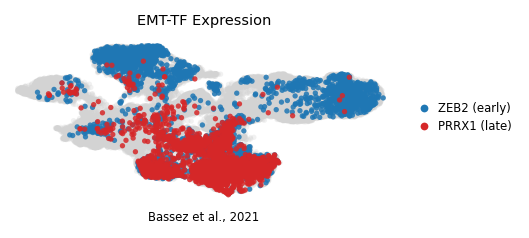

In [5]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [early_tf, late_tf]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [early_tf, late_tf]}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in [early_tf, late_tf]},
      '| cells shown:', {g: int(sel[g].sum()) for g in [early_tf, late_tf]})
order = sorted([early_tf, late_tf], key=lambda g: -int(sel[g].sum()))
colors = {early_tf:'tab:blue', late_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.85, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.legend(handles=[Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[early_tf],markersize=5,label=f'{early_tf} (early)'),
                   Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[late_tf],markersize=5,label=f'{late_tf} (late)')],
          loc='center left', bbox_to_anchor=(1.02,.5), frameon=False, fontsize=6, handletextpad=.2)
ax.set_title('EMT-TF Expression', size=7.5)
ax.text(.5,-.14,'Bassez et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
plt.show()
for g in [early_tf, late_tf]:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown (upper quartile), '
          f'mean pseudotime of shown cells = {tn[m].mean():.2f} (all = {tn.mean():.2f})')
sep = abs(tn[sel[late_tf]].mean() - tn[sel[early_tf]].mean())
print(f'shown-cell pseudotime separation ({early_tf} vs {late_tf}) = {sep:.2f}')
print('saved expression.pdf')